In [172]:
import sys

print(sys.executable)

/Users/alancastillocamet/AtmoSenseAI/.venv/bin/python


In [173]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [174]:
df_daily = pd.read_csv("../Datasets/stations_daily.csv")

print("CSV cargado correctamente")
print(df_daily.shape)

CSV cargado correctamente
(231592, 27)


In [175]:
df_rsinaica = pd.read_csv("../Datasets/stations_rsinaica.csv")

print("CSV cargado correctamente")
print(df_rsinaica.shape)

CSV cargado correctamente
(341, 27)


In [176]:
df_daily.head(5)

,datetime,station_id,PM2.5,PM10,NOx,O3,CO,HR,NO,NO2,...,HCT,HRI,IUV,PB,PP,PST,RS,TMPI,UVA,XIL
0,2015-04-02,32,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32.361000,NaN,NaN
1,2015-05-21,32,0.454967,0.347400,0.059194,0.029176,NaN,44.879091,0.029525,0.053121,...,NaN,NaN,NaN,570.775455,0.296364,NaN,7.871636,16.792818,NaN,NaN
2,2015-05-22,32,0.077821,0.389323,0.019158,0.051903,NaN,42.506000,0.009589,0.014215,...,NaN,NaN,NaN,558.360000,0.002750,NaN,384.788079,17.018949,NaN,NaN
3,2015-05-23,32,0.018036,0.387729,0.019711,0.021092,0.144603,54.734437,0.009863,0.013436,...,NaN,NaN,NaN,573.282187,0.038750,NaN,252.605975,18.575000,NaN,NaN
4,2015-05-24,32,0.024935,0.398042,0.024757,0.009568,0.494143,58.374574,0.012397,0.010337,...,NaN,NaN,NaN,572.169574,0.003404,NaN,259.231664,16.781064,NaN,NaN


In [177]:
df_daily.info()

<class 'pandas.DataFrame'>
RangeIndex: 231592 entries, 0 to 231591
Data columns (total 27 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   datetime    231592 non-null  str    
 1   station_id  231592 non-null  int64  
 2   PM2.5       161698 non-null  float64
 3   PM10        180481 non-null  float64
 4   NOx         112881 non-null  float64
 5   O3          192957 non-null  float64
 6   CO          175493 non-null  float64
 7   HR          123285 non-null  float64
 8   NO          118154 non-null  float64
 9   NO2         169286 non-null  float64
 10  TMP         127015 non-null  float64
 11  BEN         775 non-null     float64
 12  CH4         270 non-null     float64
 13  CN          595 non-null     float64
 14  CO2         56 non-null      float64
 15  H2S         280 non-null     float64
 16  HCNM        279 non-null     float64
 17  HCT         0 non-null       float64
 18  HRI         10205 non-null   float64
 19  IUV         4

In [178]:
df_rsinaica.head(5)

,station_id,station_name,station_code,network_id,network_name,network_code,street,ext,interior,colonia,...,date_validated2,passed_validation,video,lat,lon,date_started,timezone,street_view,video_interior,color
0,397,"CENICA 1, UAM Iztapalapa",CEN,144,NaN,ESTSP,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,19.489583,-98.801083,2002-01-01,"Tiempo del centro, UTC-6 (UTC-5 en verano)",NaN,NaN,Others
1,344,C. Salud Tlaxcoapán,TCP,127,NaN,TCP,NaN,NaN,NaN,NaN,...,NaN,NaN,Array,20.091472,-99.228417,NaN,"Tiempo del centro, UTC-6 (UTC-5 en verano)",NaN,NaN,Others
2,365,Costa Baja,UM,140,NaN,LAP,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,2010-03-14,"Tiempo del centro, UTC-6 (UTC-5 en verano)",NaN,NaN,Others
3,393,Unidad Móvil de Hidalgo,UMHI,143,NaN,POP,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,19.489583,-98.801083,2013-05-24,"Tiempo del centro, UTC-6 (UTC-5 en verano)",NaN,NaN,Others
4,394,Unidad Móvil Iztapalapa,UMIZ,143,NaN,POP,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,19.489583,-98.801083,2013-05-21,"Tiempo del centro, UTC-6 (UTC-5 en verano)",NaN,NaN,Others


In [179]:
df_rsinaica.info()

<class 'pandas.DataFrame'>
RangeIndex: 341 entries, 0 to 340
Data columns (total 27 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   station_id         341 non-null    int64  
 1   station_name       341 non-null    str    
 2   station_code       341 non-null    str    
 3   network_id         341 non-null    int64  
 4   network_name       334 non-null    str    
 5   network_code       340 non-null    str    
 6   street             187 non-null    str    
 7   ext                154 non-null    str    
 8   interior           74 non-null     str    
 9   colonia            186 non-null    str    
 10  zip                143 non-null    str    
 11  state_code         299 non-null    float64
 12  municipio_code     299 non-null    float64
 13  year_started       138 non-null    float64
 14  altitude           320 non-null    float64
 15  address            138 non-null    str    
 16  date_validated     20 non-null     st

#Preprocesamiento:
##Reto 1: Encontrar las estaciones que pertenecen a la red del "Valle de México"
Para eso, necesitamos unir las columnas de station_id, station_name y network_name

In [180]:
#Verificar que la cantidad de estaciones en ambos datasets sea la misma y su correspondencia
ids_datos = set(df_daily["station_id"].unique())
ids_catalogo = set(df_rsinaica["station_id"].unique())

print("Estaciones en dataset:", len(ids_datos))
print("Estaciones encontradas:", len(ids_datos & ids_catalogo))
print("Estaciones sin correspondencia:", ids_datos - ids_catalogo)

Estaciones en dataset: 78
Estaciones encontradas: 78
Estaciones sin correspondencia: set()


In [181]:
datos_completos = df_daily.merge(
    df_rsinaica[["station_id", "station_name", "network_name"]],
    on="station_id",
    how="left"
)

# Verificar resultados
print(datos_completos[
    ["station_id", "station_name", "network_name"]
].drop_duplicates())

        station_id                  station_name    network_name
0               32  Secretaría de Medio Ambiente  Aguascalientes
1420            33                        Centro  Aguascalientes
3323            53                           SUR       Chihuahua
5593            56                       CONALEP         Torreón
7361            59                           IPN         Durango
...            ...                           ...             ...
222799         359    Universidad Gto Sede Belen      Guanajuato
224419         388             Palacio Municipal         Morelia
227147         424                     Cadereyta       Monterrey
228708         425                   Universidad       Monterrey
230214         426                 Pueblo Serena       Monterrey

[78 rows x 3 columns]


In [182]:
#Verificar que en el dataset generado no existan nulos en las columnas que se usaran
datos_completos[["station_id", "station_name", "network_name"]].info()

<class 'pandas.DataFrame'>
RangeIndex: 231592 entries, 0 to 231591
Data columns (total 3 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   station_id    231592 non-null  int64
 1   station_name  231592 non-null  str  
 2   network_name  231592 non-null  str  
dtypes: int64(1), str(2)
memory usage: 5.3 MB


In [183]:
#Encontrar los id de cada estación que pertenece a la red de Valle de México
datos_ValleMex=set(datos_completos[datos_completos["network_name"] == "Valle de México"]["station_id"].unique())
print("Estaciones en Valle de México:", len(datos_ValleMex))
print("Estaciones del Valle de México:", datos_ValleMex)

Estaciones en Valle de México: 16
Estaciones del Valle de México: {np.int64(256), np.int64(258), np.int64(260), np.int64(262), np.int64(263), np.int64(266), np.int64(268), np.int64(269), np.int64(301), np.int64(271), np.int64(302), np.int64(241), np.int64(242), np.int64(244), np.int64(245), np.int64(251)}


In [184]:
#Encontrar los nombres de cada estación que pertenece a la red de Valle de México
datos_ValleMex2=set(datos_completos[datos_completos["network_name"] == "Valle de México"]["station_name"].unique())
print("Estaciones en Valle de México:", len(datos_ValleMex2))
print("Estaciones del Valle de México:", datos_ValleMex2)

Estaciones en Valle de México: 16
Estaciones del Valle de México: {'Instituto Nacional de Investigaciones Nucleares', 'Miguel Hidalgo', 'UAM Iztapalapa', 'Camarones', 'Nezahualcóyotl', 'Ajusco Medio', 'UAM Xochimilco', 'Merced', 'Tlalnepantla', 'Xalostoc', 'Centro de Ciencias de la Atmósfera', 'Santa Fe', 'Gustavo A. Madero', 'Ajusco', 'San Agustín', 'Hospital General de México'}


In [185]:
df_valle = datos_completos[
    datos_completos["station_id"].isin(datos_ValleMex)
].copy()

print("Registros del Valle de México:", len(df_valle))
print("Estaciones:", df_valle["station_id"].nunique())

Registros del Valle de México: 48223
Estaciones: 16


In [186]:
variables = ["NO2", "TMP", "HR", "O3", "CO", "PM2.5"]

faltantes_valle = df_valle[variables].isnull().sum()

porcentaje_valle = (
    df_valle[variables].isnull().mean() * 100
).round(2)

resumen_valle = pd.DataFrame({
    "Faltantes": faltantes_valle,
    "Porcentaje (%)": porcentaje_valle
})

display(resumen_valle)

,Faltantes,Porcentaje (%)
NO2,9398,19.49
TMP,27918,57.89
HR,27780,57.61
O3,3370,6.99
CO,9755,20.23
PM2.5,7854,16.29


### Análisis y selección preliminar de variables

Después de filtrar las estaciones de monitoreo de la **Zona Metropolitana del Valle de México**, obtuvimos **48,223 registros correspondientes a 16 estaciones**.

Nuestro objetivo es estimar la concentración diaria de dióxido de nitrógeno (NO₂) por estación de monitoreo, utilizando otras mediciones ambientales como variables predictoras.

Durante la exploración encontramos que la temperatura (`TMP`) y la humedad relativa (`HR`) presentan aproximadamente un 58% de valores faltantes. Por otro lado, las partículas finas (`PM2.5`) presentan únicamente un 16.29% de valores faltantes.

Por ello, decidimos comparar tres conjuntos de variables:

- **Conjunto A:** NO₂, O₃ y CO.
- **Conjunto B:** NO₂, O₃, CO, temperatura y humedad relativa.
- **Conjunto C:** NO₂, O₃, CO y PM2.5.

En los tres casos, NO₂ es la variable objetivo. También conservaremos la fecha y el identificador de la estación para el modelado.

#### Comparación de registros completos

| Conjunto | Registros completos | Porcentaje del total |
|---|---:|---:|
| A | 35,240 | 73.08% |
| B | 15,111 | 31.34% |
| C | 30,927 | 64.13% |

El conjunto A conserva la mayor cantidad de observaciones, pero utiliza solamente dos variables predictoras.

El conjunto B incorpora información meteorológica, aunque pierde una cantidad considerable de registros debido a los valores faltantes de temperatura y humedad.

Por su parte, el conjunto C conserva aproximadamente el **87.8% de los registros del conjunto A**, incorporando PM2.5 como variable predictora adicional.

#### Cobertura por estación de monitoreo

Al comparar las estaciones, observamos que el conjunto B pierde completamente los registros de las estaciones `244` y `245`.

En cambio, el conjunto C mantiene una buena cantidad de registros en las estaciones analizadas, incluyendo aquellas que quedaron excluidas del conjunto B.

Esto es importante porque buscamos desarrollar un simulador que permita estimar NO₂ en diferentes estaciones del Valle de México.

#### Conclusión preliminar

Consideramos que el **conjunto C es el candidato principal**, ya que ofrece un equilibrio entre cantidad de registros disponibles, cobertura geográfica y número de variables predictoras.

Sin embargo, todavía no podemos afirmar que sea el mejor conjunto para estimar NO₂.

Antes de tomar una decisión definitiva, analizaremos la distribución temporal de los registros, los valores atípicos y el desempeño de los modelos de regresión.

Por lo tanto, conservaremos los tres conjuntos para realizar comparaciones posteriores y determinar cuál proporciona mejores resultados de predicción.

In [187]:
variables_A = ["NO2", "O3", "CO"]
variables_B = ["NO2", "O3", "CO", "TMP", "HR"]
variables_C = ["NO2", "O3", "CO", "PM2.5"]

completos_A = df_valle[variables_A].dropna()
completos_B = df_valle[variables_B].dropna()
completos_C = df_valle[variables_C].dropna()

print("Conjunto A:", len(completos_A), "registros")
print("Conjunto B:", len(completos_B), "registros")
print("Conjunto C:", len(completos_C), "registros")

Conjunto A: 35240 registros
Conjunto B: 15111 registros
Conjunto C: 30927 registros


In [188]:
comparacion = pd.DataFrame({
    "Conjunto A": df_valle.dropna(
        subset=variables_A
    ).groupby("station_id").size(),

    "Conjunto B": df_valle.dropna(
        subset=variables_B
    ).groupby("station_id").size(),

    "Conjunto C": df_valle.dropna(
        subset=variables_C
    ).groupby("station_id").size()
}).fillna(0).astype(int)

display(comparacion)

,Conjunto A,Conjunto B,Conjunto C
station_id,,,
242,1597,1187,1521
244,2902,0,2549
245,2131,0,2015
251,2536,1064,2172
256,3313,1648,3125
258,2980,1492,2769
260,2646,1396,2423
262,2479,1347,2257
263,2033,1456,1287


In [189]:
# Comparar registros completos por año
df_A = df_valle.dropna(subset=variables_A).copy()
df_B = df_valle.dropna(subset=variables_B).copy()

df_A["anio"] = pd.to_datetime(df_A["datetime"]).dt.year
df_B["anio"] = pd.to_datetime(df_B["datetime"]).dt.year

comparacion_anios = pd.DataFrame({
    "Modelo A": df_A.groupby("anio").size(),
    "Modelo B": df_B.groupby("anio").size()
}).fillna(0).astype(int)

display(comparacion_anios)

,Modelo A,Modelo B
anio,,
2010,1534,0
2012,3222,0
2013,3072,0
2014,2694,0
2015,4044,0
2016,1906,1537
2017,3991,3169
2018,4126,3022
2019,3791,2599


In [190]:
df_A = df_valle.dropna(subset=variables_A).copy()
df_B = df_valle.dropna(subset=variables_B).copy()
df_C = df_valle.dropna(subset=variables_C).copy()

for datos in [df_A, df_B, df_C]:
    datos["anio"] = pd.to_datetime(datos["datetime"]).dt.year

comparacion_anios = pd.DataFrame({
    "Conjunto A": df_A.groupby("anio").size(),
    "Conjunto B": df_B.groupby("anio").size(),
    "Conjunto C": df_C.groupby("anio").size()
}).fillna(0).astype(int)

display(comparacion_anios)

,Conjunto A,Conjunto B,Conjunto C
anio,,,
2010,1534,0,1103
2012,3222,0,3069
2013,3072,0,3007
2014,2694,0,2417
2015,4044,0,3722
2016,1906,1537,1542
2017,3991,3169,3386
2018,4126,3022,3760
2019,3791,2599,3424


In [191]:
#Detectamos valores atipicos
columnas = ["NO2", "O3", "CO", "PM2.5", "TMP", "HR"]

df_valle[columnas].describe().round(2)

,NO2,O3,CO,PM2.5,TMP,HR
count,38825.00,44853.00,38468.00,40369.00,20305.00,20443.00
mean,0.03,0.03,0.76,22.94,17.00,53.42
std,0.01,0.01,0.32,10.91,3.05,15.08
min,0.00,0.00,0.00,0.00,0.00,0.00
25%,0.02,0.02,0.54,15.33,15.37,42.92
50%,0.03,0.03,0.72,21.46,17.24,54.13
75%,0.03,0.04,0.93,28.62,18.93,63.96
max,0.10,0.10,5.39,189.50,105.00,100.00


In [192]:
# Revisar temperaturas fuera de un rango preliminar
temperaturas_atipicas = df_valle[
    (df_valle["TMP"] < -10) |
    (df_valle["TMP"] > 45)
]

print("Temperaturas atípicas:", len(temperaturas_atipicas))

display(
    temperaturas_atipicas[
        ["datetime", "station_id", "TMP"]
    ].sort_values("TMP", ascending=False).head(20)
)

# Reemplazar temperaturas fuera del rango válido por NaN
df_valle.loc[
    (df_valle["TMP"] < -10) |
    (df_valle["TMP"] > 45),
    "TMP"
] = np.nan

Temperaturas atípicas: 1


,datetime,station_id,TMP
209962,2018-08-24,301,105.0


Se detectó una temperatura atípica de **105 °C**,
por lo que se reemplazó por un valor nulo (`NaN`).

In [193]:
# Contar valores iguales a cero
columnas = ["NO2", "O3", "CO", "PM2.5", "TMP", "HR"]

for columna in columnas:
    ceros = (df_valle[columna] == 0).sum()
    print(f"{columna}: {ceros} valores en cero")

NO2: 1 valores en cero
O3: 2 valores en cero
CO: 14 valores en cero
PM2.5: 16 valores en cero
TMP: 1 valores en cero
HR: 2 valores en cero


Verificamos datos iguales a 0 principalmente en humedad por que es imposible que haya 0.0 de humedad en el Valle de México.

In [194]:
# Revisar los registros con humedad relativa igual a cero
df_valle.loc[
    df_valle["HR"] == 0,
    ["datetime", "station_id", "HR", "TMP"]
]

,datetime,station_id,HR,TMP
169800,2018-03-05,251,0.0,0.0
195543,2018-06-13,268,0.0,24.0


In [195]:
# Identificar humedades sospechosas
humedad_invalida = df_valle["HR"] == 0

print("Valores de humedad a corregir:", humedad_invalida.sum())

# Reemplazar por NaN
df_valle.loc[humedad_invalida, "HR"] = np.nan

Valores de humedad a corregir: 2


In [196]:
duplicados = df_valle.duplicated(
    subset=["datetime", "station_id"]
)

print("Registros duplicados:", duplicados.sum())

Registros duplicados: 0


### Análisis de valores atípicos

Se realizaron diagramas de caja (*boxplots*) para analizar la distribución de NO₂, O₃, CO y PM2.5.

Observamos que PM2.5 tiene valores mucho mayores que los demás contaminantes, por lo que dificulta visualizar sus distribuciones en una misma gráfica.

Por esta razón, decidimos generar gráficas individuales para cada variable.

También identificamos valores atípicos, pero no los eliminaremos todavía, ya que podrían representar episodios reales de contaminación y no necesariamente errores de medición.

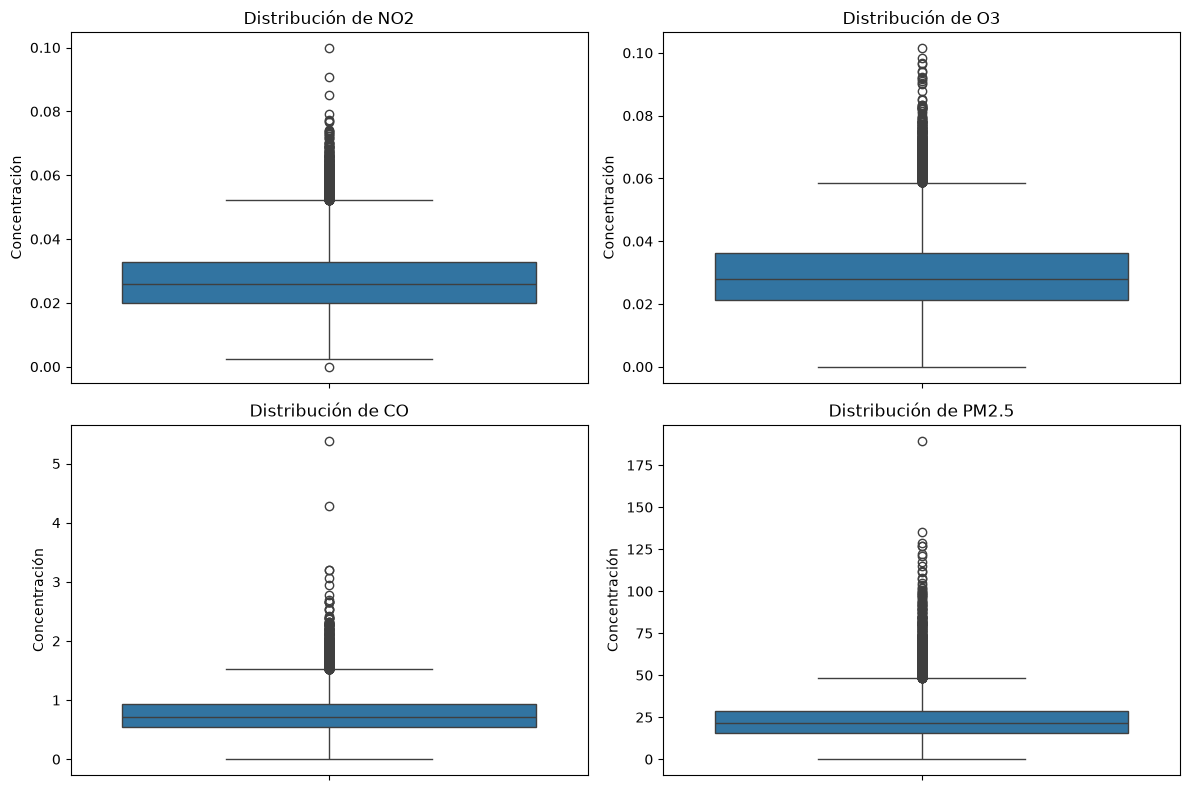

In [197]:
columnas = ["NO2", "O3", "CO", "PM2.5"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, columna in zip(axes.flatten(), columnas):
    sns.boxplot(y=df_valle[columna], ax=ax)
    ax.set_title(f"Distribución de {columna}")
    ax.set_ylabel("Concentración")

plt.tight_layout()
plt.show()

### Interpretación de los diagramas de caja

Al analizar cada contaminante por separado, observamos que NO₂, O₃, CO y PM2.5 presentan valores atípicos superiores a sus rangos habituales.

Estos valores no necesariamente representan errores, ya que podrían corresponder a días con concentraciones elevadas de contaminación.

Por esta razón, decidimos conservarlos por el momento y evitar eliminar información que podría ser útil para el entrenamiento de los modelos.

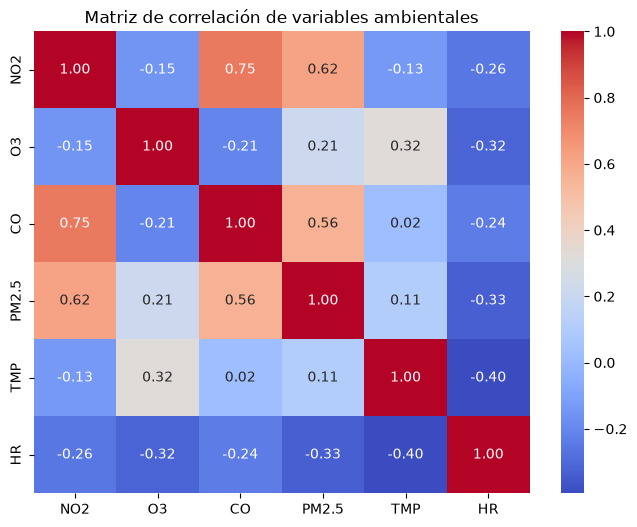

In [198]:
columnas = ["NO2", "O3", "CO", "PM2.5", "TMP", "HR"]

correlacion = df_valle[columnas].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(correlacion, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Matriz de correlación de variables ambientales")
plt.show()

### Análisis de correlación

Se calculó una matriz de correlación para identificar las relaciones entre las variables ambientales y la concentración de NO₂.

Observamos que CO (0.75) y PM2.5 (0.62) presentan las correlaciones positivas más altas con NO₂. Por otro lado, O₃, temperatura y humedad muestran correlaciones negativas débiles.

Estos resultados apoyan la selección preliminar del conjunto C, formado por O₃, CO y PM2.5 como variables predictoras.

Sin embargo, conservaremos los tres conjuntos para comparar posteriormente su desempeño mediante los modelos de regresión.

In [199]:
conjuntos = {
    "A": variables_A,
    "B": variables_B,
    "C": variables_C
}

for nombre, variables in conjuntos.items():
    datos = df_valle.dropna(subset=variables)

    print(f"Conjunto {nombre}:")
    print("Registros:", len(datos))
    print("Estaciones:", datos["station_id"].nunique())
    print("Fecha inicial:", datos["datetime"].min())
    print("Fecha final:", datos["datetime"].max())
    print()

Conjunto A:
Registros: 35240
Estaciones: 13
Fecha inicial: 2010-01-01
Fecha final: 2021-12-31

Conjunto B:
Registros: 15109
Estaciones: 11
Fecha inicial: 2016-06-22
Fecha final: 2021-12-31

Conjunto C:
Registros: 30927
Estaciones: 13
Fecha inicial: 2010-01-01
Fecha final: 2021-12-31



In [200]:
# Identificar estaciones sin registros completos
estaciones_valle = set(df_valle["station_id"].unique())
estaciones_C = set(
    df_valle.dropna(subset=variables_C)["station_id"].unique()
)

estaciones_excluidas = estaciones_valle - estaciones_C

print("Estaciones excluidas del conjunto C:")
print(sorted(estaciones_excluidas))

Estaciones excluidas del conjunto C:
[np.int64(241), np.int64(301), np.int64(302)]


In [201]:
# Revisar la disponibilidad de datos en las estaciones excluidas
estaciones_excluidas = [241, 301, 302]

revision = df_valle[
    df_valle["station_id"].isin(estaciones_excluidas)
]

print("Registros por estación:")
display(revision.groupby("station_id").size())

print("Valores disponibles por variable:")
display(
    revision.groupby("station_id")[variables_C].count()
)

Registros por estación:


station_id
241    1297
301    1188
302    1872
dtype: int64

Valores disponibles por variable:


,NO2,O3,CO,PM2.5
station_id,,,,
241,0,1190,0,687
301,0,1150,1142,864
302,1025,1860,0,1240


### Revisión de estaciones excluidas

De las 16 estaciones identificadas en el Valle de México, únicamente 13 cuentan con registros completos para el conjunto C.

Las estaciones 241 y 301 no tienen mediciones de NO₂, mientras que la estación 302 no tiene registros de CO.

Por esta razón, estas tres estaciones no se utilizarán para entrenar el conjunto C, aunque se conservarán en el dataset general para posibles análisis posteriores.

Finalmente, el conjunto C mantiene **30,927 registros completos de 13 estaciones de monitoreo**.

In [202]:
# Rangos observados para el conjunto C
columnas = ["NO2", "O3", "CO", "PM2.5"]

rangos = df_valle[columnas].agg(["min", "max", "mean"])

display(rangos.round(4))

,NO2,O3,CO,PM2.5
min,0.0000,0.0000,0.0000,0.0000
max,0.0998,0.1015,5.3857,189.5000
mean,0.0270,0.0295,0.7590,22.9355


In [203]:
columnas = ["NO2", "O3", "CO", "PM2.5"]

percentiles = df_valle[columnas].quantile([0.01, 0.99])

percentiles.index = ["Percentil 1", "Percentil 99"]

display(percentiles.round(4))

,NO2,O3,CO,PM2.5
Percentil 1,0.0098,0.0073,0.1650,5.5000
Percentil 99,0.0546,0.0626,1.6792,56.8284
